In [39]:

# Website A/B Testing: White vs Black Background
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind





In [2]:
# 1. Load the CSV file
df = pd.read_csv("ab_testing.csv")

In [3]:
print("FIRST 5 ROWS")
print(df.head())

FIRST 5 ROWS
   User ID Group  Page Views  Time Spent Conversion   Device          Location
0    14292     B           3         424         No   Mobile  Northern Ireland
1    11682     A           9         342         No   Mobile          Scotland
2    19825     A           2         396         No  Desktop  Northern Ireland
3    16080     B           4         318         No  Desktop             Wales
4    18851     A           1         338        Yes  Desktop          Scotland


In [4]:
# 2. Understand the dataset
print("\nDATASET SHAPE")
print(df.shape)


DATASET SHAPE
(5000, 7)


In [5]:
print("\nCOLUMN NAMES")
print(df.columns.tolist())


COLUMN NAMES
['User ID', 'Group', 'Page Views', 'Time Spent', 'Conversion', 'Device', 'Location']


In [6]:
print("\nMISSING VALUES")
print(df.isnull().sum())


MISSING VALUES
User ID       0
Group         0
Page Views    0
Time Spent    0
Conversion    0
Device        0
Location      0
dtype: int64


In [7]:
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())


DUPLICATE ROWS
0


In [8]:
# 3. Clean the data
df = df.drop_duplicates()

In [9]:
df["Group"] = df["Group"].astype(str).str.strip().str.upper()
df["Time Spent"] = pd.to_numeric(
    df["Time Spent"], errors="coerce"
)

In [10]:
df = df.dropna(subset=["Group", "Time Spent"])

In [11]:
# Keep only the two experiment groups
df = df[df["Group"].isin(["A", "B"])]

# Assumption: A = White, B = Black
df["Background"] = df["Group"].map({
    "A": "White",
    "B": "Black"
})

In [12]:
# 4. Check sample sizes
print("\nUSERS IN EACH GROUP")
print(df["Background"].value_counts())


USERS IN EACH GROUP
Background
White    2519
Black    2481
Name: count, dtype: int64


In [13]:
# 5. Calculate time-spent statistics
summary = df.groupby("Background")["Time Spent"].agg(
    ["count", "mean", "median", "std"]
)

In [14]:
print("\nTIME SPENT SUMMARY")
print(summary.round(2))


TIME SPENT SUMMARY
            count    mean  median     std
Background                               
Black        2481  243.30   244.0  119.19
White        2519  241.73   241.0  117.34


In [15]:
white = df.loc[
    df["Background"] == "White", "Time Spent"
]

black = df.loc[
    df["Background"] == "Black", "Time Spent"
]

In [16]:
# 6. Calculate the difference between groups
difference = black.mean() - white.mean()

percentage_change = (
    difference / white.mean()
) * 100


In [17]:
print("\nAVERAGE TIME DIFFERENCE (BLACK - WHITE)")
print(round(difference, 2))

print("\nPERCENTAGE CHANGE")
print(round(percentage_change, 2), "%")


AVERAGE TIME DIFFERENCE (BLACK - WHITE)
1.57

PERCENTAGE CHANGE
0.65 %


In [18]:
# 7. Perform Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(
    black, white, equal_var=False
)

In [19]:
print("\nWELCH'S T-TEST")
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))


WELCH'S T-TEST
T-statistic: 0.4695
P-value: 0.6387


In [20]:
# 8. Interpret the result
alpha = 0.05

if p_value < alpha:
    print(
        "Result: Statistically significant difference "
        "in average time spent."
    )
else:
    print(
        "Result: No statistically significant difference "
        "in average time spent."
    )

Result: No statistically significant difference in average time spent.


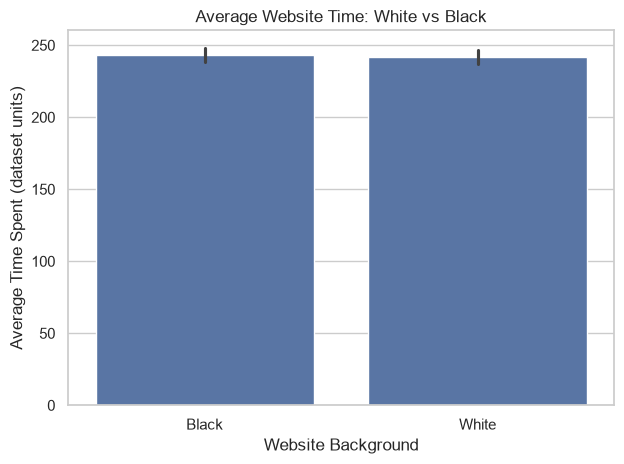

In [ ]:
# 9. Visualize average time spent
sns.set_theme(style="whitegrid")

sns.barplot(
    data=df,
    x="Background",
    y="Time Spent",
    estimator="mean",
    errorbar=("ci", 95)
)


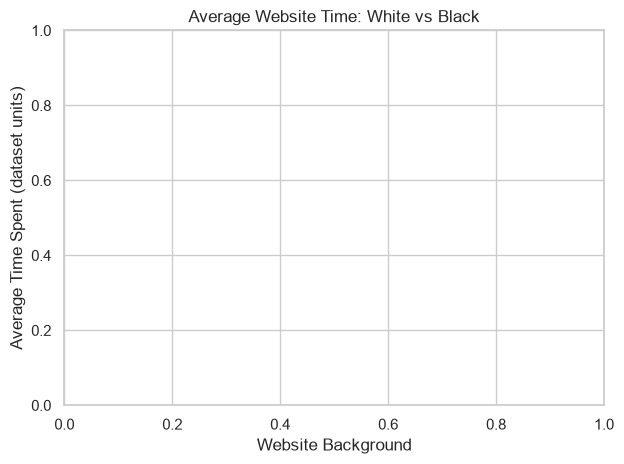

In [22]:
plt.title("Average Website Time: White vs Black")
plt.xlabel("Website Background")
plt.ylabel("Average Time Spent (dataset units)")
plt.tight_layout()
plt.savefig("average_time_comparison.png", dpi=300)
plt.show()

<Axes: xlabel='Background', ylabel='Time Spent'>

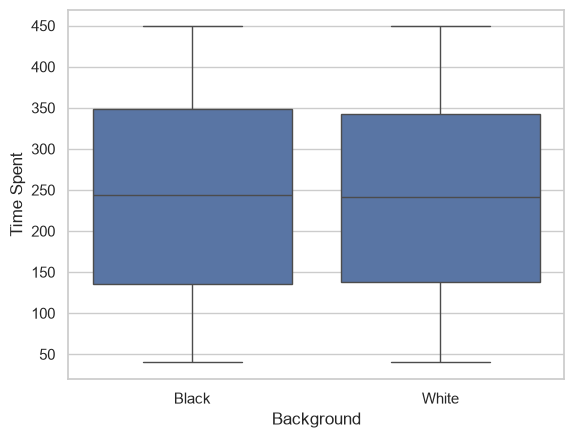

In [24]:
# 10. Visualize the distribution
sns.boxplot(
    data=df,
    x="Background",
    y="Time Spent"
)


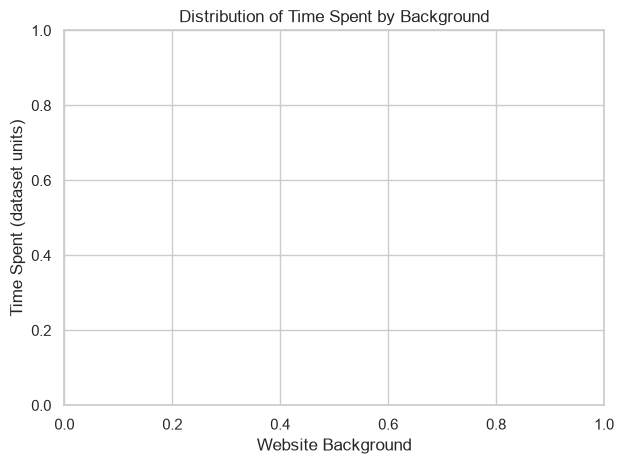

In [25]:
plt.title("Distribution of Time Spent by Background")
plt.xlabel("Website Background")
plt.ylabel("Time Spent (dataset units)")
plt.tight_layout()
plt.savefig("time_spent_distribution.png", dpi=300)
plt.show()

In [28]:
# 11. Optional: Explore conversion rates
if "Conversion" in df.columns:
    conversion_rate = (
        df.assign(
            Converted=df["Conversion"]
            .astype(str).str.strip().str.lower()
            .eq("yes")
        )
        .groupby("Background")["Converted"]
        .mean() * 100
    )
    print("\nCONVERSION RATE (%)")
    print(conversion_rate.round(2))



CONVERSION RATE (%)
Background
Black    14.07
White     5.40
Name: Converted, dtype: float64


In [32]:
print(df.columns.tolist())

['User ID', 'Group', 'Page Views', 'Time Spent', 'Conversion', 'Device', 'Location', 'Background']


In [34]:

print(df.dtypes)

print("\nSample rows:")
print(df[['User ID', 'Page Views', 'Conversion', 'Background']].head(10))

print("\nConversion values:")
print(df['Conversion'].value_counts(dropna=False))


User ID       int64
Group           str
Page Views    int64
Time Spent    int64
Conversion      str
Device          str
Location        str
Background      str
dtype: object

Sample rows:
   User ID  Page Views Conversion Background
0    14292           3         No      Black
1    11682           9         No      White
2    19825           2         No      White
3    16080           4         No      Black
4    18851           1        Yes      White
5    13134           2         No      Black
6    16702           5         No      White
7    10041           9         No      Black
8    13191           8         No      Black
9    14427          12         No      Black

Conversion values:
Conversion
No     4515
Yes     485
Name: count, dtype: int64


In [35]:

df['Converted'] = df['Conversion'].map({
    'Yes': 1,
    'No': 0
})

print(df[['Conversion', 'Converted']].head(10))


  Conversion  Converted
0         No          0
1         No          0
2         No          0
3         No          0
4        Yes          1
5         No          0
6         No          0
7         No          0
8         No          0
9         No          0


In [36]:
#13Calculate the conversion rate for each background

conversion_summary = df.groupby('Background').agg(
    Total_Visitors=('User ID', 'count'),
    Total_Page_Views=('Page Views', 'sum'),
    Conversions=('Converted', 'sum'),
    Conversion_Rate=('Converted', 'mean')
)

conversion_summary['Conversion_Rate'] *= 100

print(conversion_summary.round(2))


            Total_Visitors  Total_Page_Views  Conversions  Conversion_Rate
Background                                                                
Black                 2481             18590          349            14.07
White                 2519             19098          136             5.40


In [ ]:
#14.install statsmodels to calculate p value 
from statsmodels.stats.proportion import proportions_ztest
print("statsmodels imported successfully!")


statsmodels imported successfully!


In [44]:
#15.Calculate the p-value

conversions = [349, 136]  # Black, White
visitors = [2481, 2519]   # Black, White

z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=visitors,
    alternative='two-sided'
)

print("Z-statistic:", round(z_stat, 4))
print("P-value:", f"{p_value:.10e}")

if p_value < 0.05:
    print("Statistically significant difference")
else:
    print("Not statistically significant")


Z-statistic: 10.3545
P-value: 3.9931511894e-25
Statistically significant difference


In [45]:
#Q2.Does the black background lead to more conversions, longer engagement, or both?
# 15. Compare average time spent by background

time_summary = df.groupby('Background')['Time Spent'].agg(
    Total_Visitors='count',
    Average_Time='mean',
    Median_Time='median'
)

print(time_summary.round(2))


            Total_Visitors  Average_Time  Median_Time
Background                                           
Black                 2481        243.30        244.0
White                 2519        241.73        241.0


In [46]:
#Test whether the difference is statistically significant

from scipy.stats import ttest_ind

black_time = df.loc[
    df['Background'] == 'Black', 'Time Spent'
].dropna()

white_time = df.loc[
    df['Background'] == 'White', 'Time Spent'
].dropna()

t_stat, p_value = ttest_ind(
    black_time,
    white_time,
    equal_var=False,
    alternative='two-sided'
)

print("Black average:", round(black_time.mean(), 2))
print("White average:", round(white_time.mean(), 2))
print("Mean difference:", round(
    black_time.mean() - white_time.mean(), 2
))
print("T-statistic:", round(t_stat, 4))
print("P-value:", f"{p_value:.10e}")

if p_value < 0.05:
    print("Statistically significant difference in average time.")
else:
    print("No statistically significant difference in average time.")


Black average: 243.3
White average: 241.73
Mean difference: 1.57
T-statistic: 0.4695
P-value: 6.3873803831e-01
No statistically significant difference in average time.
